# 1. The scenario

> Set up the environment used throughout the series: SPICE kernels, units, time, reference frames and celestial bodies, the OSIRIS-REx spacecraft, and the DSN stations that track it.
>
> ⏱ ~10 min &nbsp;·&nbsp; **Prereqs:** none ([Quickstart](00_quickstart.ipynb) recommended) &nbsp;·&nbsp; **Next:** [2. Truth: dynamics & propagation](02_truth_dynamics.ipynb)

**Scenario.** In June 2018, OSIRIS-REx was five months from its arrival at the near-Earth asteroid Bennu. This series navigates one week of that approach, June 1–8, 2018: first with simulated tracking data, and in the final chapter with the real DSN data from the same week.

This chapter does not yet involve orbit determination. It introduces the core Scarabaeus objects used by every later chapter; each has a dedicated page in *Fundamentals* for further detail.

<div style="border-left:4px solid #16a34a; background:rgba(22,163,74,0.12); padding:6px 10px; border-radius:4px">
🟢 <b>IDEA:</b> example review note (see “Review notes” in README.md). Delete this cell once you've seen how it renders.
</div>

In [1]:
import matplotlib.pyplot as plt
import scarabaeus as scb

## 1. SPICE kernels

Scarabaeus relies on NASA's [SPICE toolkit](https://naif.jpl.nasa.gov/naif/) for time conversion, ephemerides, body constants and reference-frame definitions. The data SPICE uses are provided as *kernels*; the series uses a single metakernel, `orex_approach.tm`, which lists:

| Kernel | Provides |
|---|---|
| `naif0012.tls` | leap seconds (UTC ↔ TDB) |
| `pck00010.tpc`, `gm_de431.tpc` | body shapes, orientation models, gravitational parameters |
| `de424.bsp`, `mar099s.bsp`, `jup310.bsp`, `sat360.bsp` | planetary ephemerides |
| `earth_000101_…bpc`, `earth_topo_201023.tf`, `earth_assoc_itrf93.tf` | high-precision Earth orientation and topocentric station frames |
| `earthstns_itrf93_201023.bsp` | DSN station locations |
| `bennu_v17.tpc` | Bennu constants |
| `orx_180301_181201_180921_od044_v1.bsp` | OSIRIS-REx and Bennu trajectories, as reconstructed by the flight navigation team |

Once loaded, the kernel pool is shared by all Scarabaeus objects: any object that needs a position, a rotation or a time conversion retrieves it from the pool.

→ *Fundamentals: SPICE, bodies & constants*

In [2]:
scb.SpiceManager.clear_kernels()
scb.SpiceManager.load_kernel_from_mkfile("orex_approach.tm")
scb.SpiceManager.print_kernels()

                                 Kernels Loaded:
Source:   orex_approach.tm   (META)
Source:   ../supplementary/supp_data/kernels/locked/lsk/naif0012.tls   (TEXT)
Source:   ../supplementary/supp_data/kernels/locked/pck/pck00010.tpc   (TEXT)
Source:   ../supplementary/supp_data/kernels/locked/pck/gm_de431.tpc   (TEXT)
Source:   ../supplementary/supp_data/kernels/locked/spk/de424.bsp   (SPK)
Source:   ../supplementary/supp_data/kernels/scenario/earth_000101_250127_241031.bpc   (PCK)
Source:   ../supplementary/supp_data/kernels/locked/spk/earthstns_itrf93_201023.bsp   (SPK)
Source:   ../supplementary/supp_data/kernels/locked/spk/earth_topo_201023.tf   (TEXT)
Source:   ../supplementary/supp_data/kernels/validation/earth_assoc_itrf93.tf   (TEXT)
Source:   ../supplementary/supp_data/kernels/locked/spk/mar099s.bsp   (SPK)
Source:   ../supplementary/supp_data/kernels/scenario/jup310.bsp   (SPK)
Source:   ../supplementary/supp_data/kernels/scenario/sat360.bsp   (SPK)
Source:   ../supplementary/

## 2. Units

Physical quantities in Scarabaeus are `ArrayWUnits` objects, values with attached units, so dimensional inconsistencies raise errors rather than propagate silently. The units used in this chapter:

In [3]:
kg, km, m, sec, minute, day, AU = scb.Units.get_units(
    ["kg", "km", "m", "sec", "min", "day", "AU"]
)

offset = scb.ArrayWUnits(1.0, km) + scb.ArrayWUnits(250.0, m).convert_to(km)
print(offset)

try:
    scb.ArrayWUnits(1.0, km) + scb.ArrayWUnits(1.0, km / sec)
except ValueError as err:
    print("ValueError:", err)

1.25 km
ValueError: Addition operator is only defined for ArrayWUnits objects containing like units. Received: km + km/sec.


Addition and subtraction require identical units (`km + m` also raises), so quantities are converted explicitly with `convert_to`, which returns a new `ArrayWUnits` and leaves the original unchanged.

→ *Fundamentals: Units & ArrayWUnits*

## 3. Time

Tracking data are time-tagged in UTC, while ephemerides and dynamics use TDB, which SPICE represents as ephemeris time (ET, seconds past J2000). An `EpochArray` stores epochs in a single uniform time system and converts between representations on demand.

The arc is one week sampled every 30 minutes. The endpoints are specified in UTC, converted to ET, and passed to `EpochArray.interval`:

In [4]:
t0 = scb.SpiceManager.utc2et("2018-06-01T00:00:00")
tf = scb.SpiceManager.utc2et("2018-06-08T00:00:00")

epochs = scb.EpochArray.interval(t0, tf, dt=scb.ArrayWUnits(30, minute), sys="TDB")

print(f"{epochs.size} epochs spanning {epochs.duration(day)}")
print("first:", epochs[0], "=", epochs[0].to(rep="ISOC"))
print("last: ", epochs[-1], "=", epochs[-1].to(rep="ISOC"))

336 epochs spanning 6.979166666666666 day
first: 581083269.1849095 sec (TDB) = 2018-06-01T00:01:09.1849 (TDB)
last:  581686269.1849095 sec (TDB) = 2018-06-07T23:31:09.1849 (TDB)


Notes:

- With a step `dt`, `interval` is **half-open**, $[t_0, t_f)$: the last epoch is 23:30 UTC on June 7. Use `n_epochs=` instead of `dt=` for a closed interval.
- The calendar and ISO representations are displayed in the array's own time system, shown by the `(TDB)` tag. TDB − UTC ≈ 69.18 s in 2018, so UTC midnight on June 1 displays as 00:01:09.18 TDB, and the numeric value `581083269.18 sec` is the same instant as ephemeris time (TDB seconds past J2000).
- Differences between epochs are `ArrayWUnits` durations: `(epochs - epochs[0]).convert_to(day)` gives the elapsed time in days, used for plotting below.

→ *Fundamentals: Time & EpochArray*

## 4. Frames and celestial bodies

Dynamics are expressed in the J2000 inertial frame, centered on the Sun. `CelestialBody.from_constants` creates a body with its gravitational parameter, mean radius and body-fixed frame populated from the built-in constants:

In [5]:
J2000 = scb.Frame("J2000")
ECLIPJ2000 = scb.Frame("ECLIPJ2000")

sun = scb.CelestialBody.from_constants("SUN")
earth = scb.CelestialBody.from_constants("EARTH")

print(f"Sun:   GM = {sun.grav_param},  R = {sun.mean_radius}")
print(
    f"Earth: GM = {earth.grav_param},  R = {earth.mean_radius},  body-fixed frame = {earth.base_frame}"
)

Sun:   GM = 132712440041.939 mu,  R = 696000.0 km
Earth: GM = 398600.435436096 mu,  R = 6371.0084 km,  body-fixed frame = ITRF93 (399 - EARTH)


`mu` is the unit Scarabaeus uses for gravitational parameters (km³/s²). Bodies without built-in constants, such as Bennu, can be created as a generic `Body` from their SPICE ID; this is sufficient for anything that only needs their ephemeris.

→ *Fundamentals: Frames & ArrayWFrame; SPICE, bodies & constants*

In [6]:
bennu = scb.Body("Bennu", 2101955)

## 5. OSIRIS-REx

A `Spacecraft` is a `Body` with a SPICE ID and, optionally, physical properties. The flight-reconstructed OSIRIS-REx trajectory is in the kernel pool under ID `-64`, so a spacecraft with that ID can be queried for its state directly:

In [7]:
orex_flight = scb.Spacecraft("OSIRIS-REx (flight)", -64)

x0 = orex_flight.get_state(epochs[0], reference_frame="J2000", origin="SUN")
print(x0)

[-8.55864067e+07 -1.52246038e+08 -8.71649152e+07  2.04430193e+01
 -9.90506386e+00 -5.64838191e+00] [non-homogeneous] (J2000 (0 - SOLAR SYSTEM BARYCENTER))


`x0` is an `ArrayWFrame`: an `ArrayWUnits` (here with mixed units, km and km/s) associated with a reference frame. The state is Sun-relative, as requested; the `(0 - SOLAR SYSTEM BARYCENTER)` in the tag is the default origin of the J2000 frame object, not the origin of this vector.

Slicing the underlying `quantity` preserves units. The position and velocity obtained this way are the initial conditions used in [chapter 2](02_truth_dynamics.ipynb):

In [8]:
r0, v0 = x0.quantity[:3], x0.quantity[3:]
print("r0 =", r0)
print("v0 =", v0)

r_sun = r0.norm().convert_to(AU)
r_earth = (
    orex_flight.get_state(epochs[0], reference_frame="J2000", origin="EARTH")
    .quantity[:3]
    .norm()
    .convert_to(AU)
)
r_bennu = (
    orex_flight.get_state(epochs[0], reference_frame="J2000", origin="BENNU")
    .quantity[:3]
    .norm()
)
print(
    f"\nOn June 1, 2018 OSIRIS-REx is {float(r_sun.values):.3f} AU from the Sun, "
    f"{float(r_earth.values):.3f} AU from Earth, and {float(r_bennu.values):.3e} km from Bennu."
)

r0 = [-8.55864067e+07 -1.52246038e+08 -8.71649152e+07] [km ... km]
v0 = [20.44301932 -9.90506386 -5.64838191] [km/sec ... km/sec]

On June 1, 2018 OSIRIS-REx is 1.305 AU from the Sun, 0.338 AU from Earth, and 8.646e+06 km from Bennu.


### Approach geometry

Repeating the same query over a longer interval shows the approach geometry. The flight SPK covers March–November 2018; the week used in this series is highlighted.

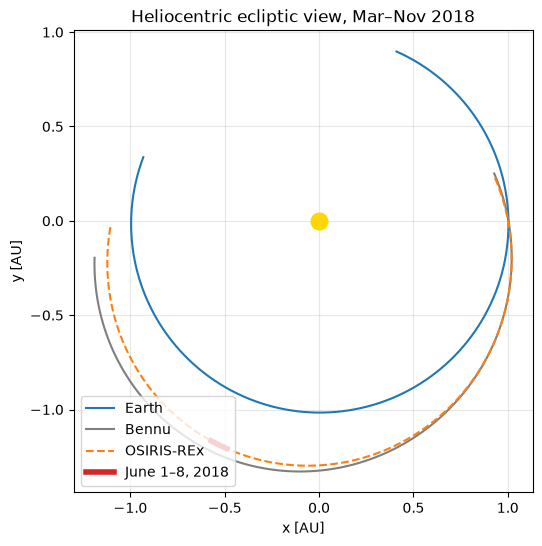

In [9]:
season = scb.EpochArray.interval(
    scb.SpiceManager.utc2et("2018-03-01T00:00:00"),
    scb.SpiceManager.utc2et("2018-11-30T00:00:00"),
    dt=scb.ArrayWUnits(2, day),
    sys="TDB",
)


# TODO(draft): get_state takes one epoch at a time; replace this loop once it accepts an EpochArray
def xy(body, times):
    return zip(
        *[
            body.get_state(t, "ECLIPJ2000", "SUN").quantity[:2].convert_to(AU).values
            for t in times
        ]
    )


fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(*xy(earth, season), color="tab:blue", label="Earth")
ax.plot(*xy(bennu, season), color="tab:gray", label="Bennu")
ax.plot(*xy(orex_flight, season), "--", color="tab:orange", label="OSIRIS-REx")
ax.plot(*xy(orex_flight, epochs), color="tab:red", lw=4, label="June 1–8, 2018")
ax.plot(0, 0, "o", color="gold", ms=12)
ax.set(
    xlabel="x [AU]",
    ylabel="y [AU]",
    title="Heliocentric ecliptic view, Mar–Nov 2018",
    aspect="equal",
)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)

## 6. Simulated spacecraft

Testing a navigation pipeline requires a truth that is fully known. From [chapter 2](02_truth_dynamics.ipynb) onward, the **truth** is a trajectory propagated by Scarabaeus from the flight state above, with physical properties chosen here. That trajectory is written to its own SPK, so it needs its own SPICE ID; `-64` is already used by the flight reconstruction in the kernel pool. [Chapter 4](04_filter_dynamics.ipynb) adds a third spacecraft, the filter's **reference**, with another ID.

Mass, cross-sectional area and reflectivity coefficient define the solar radiation pressure (SRP) acceleration. The values below reproduce the flight trajectory to within a few hundred meters over the week (chapter 2); [chapter 8](08_estimating_more.ipynb) estimates the SRP scale factor instead of assuming it.

In [10]:
mass = scb.ArrayWUnits(1500.0, kg)
area = scb.ArrayWUnits(11.0, m**2)
cr = scb.ArrayWUnits(1.2, None)

orex = scb.Spacecraft("OREx truth", -64000, mass, area.convert_to(km**2), cr)
print(
    f"{orex.name} (SPICE ID {orex.spice_id}): mass {orex.mass()}, SRP area {area}, Cr {cr}"
)

OREx truth (SPICE ID -64000): mass 1500.0 kg, SRP area 11.0 m^2, Cr 1.2 unitless


## 7. Station visibility

The Deep Space Network has three complexes spaced roughly 120° apart in longitude: Goldstone (DSS-14), Canberra (DSS-43) and Madrid (DSS-63). A `GroundStation` is defined by its SPICE name; its location and topocentric frame come from the station kernels. `station_visibility` returns, for each epoch, whether the spacecraft is above an elevation mask, together with its elevation and azimuth:

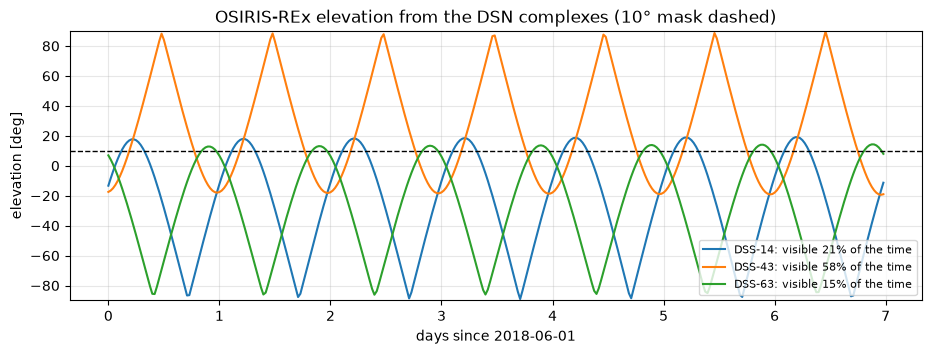

In [11]:
stations = {dss: scb.GroundStation(dss) for dss in ["DSS-14", "DSS-43", "DSS-63"]}
days = (epochs - epochs[0]).convert_to(day).values

fig, ax = plt.subplots(figsize=(11, 3.5))
for dss, gs in stations.items():
    visible, elevation, azimuth = gs.station_visibility(
        orex_flight, epochs, elevation_mask=10.0, return_angles=True
    )
    ax.plot(days, elevation, label=f"{dss}: visible {visible.mean():.0%} of the time")
ax.axhline(10.0, color="k", ls="--", lw=1)
ax.set(
    xlabel="days since 2018-06-01",
    ylabel="elevation [deg]",
    ylim=(-90, 90),
    title="OSIRIS-REx elevation from the DSN complexes (10° mask dashed)",
)
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)

At this southern declination, Canberra has the longest passes and Madrid the shortest. The same asymmetry appears in the simulated tracking schedule in [chapter 3](03_tracking_data.ipynb).

## Summary

| Concept | Scarabaeus API |
|---|---|
| Kernel management | `SpiceManager.load_kernel_from_mkfile`, `SpiceManager.print_kernels`, `SpiceManager.utc2et` |
| Quantities with units | `Units.get_units`, `ArrayWUnits`, `convert_to`, `norm` |
| Time | `EpochArray.interval`, `.to(rep=...)`, `.duration`, epoch differences |
| Frames and bodies | `Frame`, `CelestialBody.from_constants`, `Body` |
| States | `Body.get_state` → `ArrayWFrame` |
| Spacecraft | `Spacecraft(name, spice_id, mass, area, cr)` |
| Stations | `GroundStation`, `station_visibility` |

The scenario reduces to the following setup, which [chapter 2](02_truth_dynamics.ipynb) starts from:

```python
import scarabaeus as scb

scb.SpiceManager.load_kernel_from_mkfile("orex_approach.tm")
kg, km, m, sec, minute, day = scb.Units.get_units(["kg", "km", "m", "sec", "min", "day"])
J2000 = scb.Frame("J2000")
sun = scb.CelestialBody.from_constants("SUN")

epochs = scb.EpochArray.interval(scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
                                 scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
                                 dt=scb.ArrayWUnits(30, minute), sys="TDB")

orex_flight = scb.Spacecraft("OSIRIS-REx (flight)", -64)
x0 = orex_flight.get_state(epochs[0], reference_frame="J2000", origin="SUN")
r0, v0 = x0.quantity[:3], x0.quantity[3:]

orex = scb.Spacecraft("OREx truth", -64000, scb.ArrayWUnits(1500.0, kg),
                      scb.ArrayWUnits(11.0, m**2).convert_to(km**2), scb.ArrayWUnits(1.2, None))
```

**Next:** [2. Truth: dynamics & propagation](02_truth_dynamics.ipynb) propagates `r0, v0` into a truth trajectory, compares force-model choices against the flight reconstruction, and saves the result as an SPK.